CDS 230 - Lab 5: K-means Clustering

Student 1: Doungmin Shin  
Student 2: Seunghyun Park

Dataset: Wholesale Customers

Dataset Source: https://archive.ics.uci.edu/dataset/292/wholesale+customers

In [19]:
# call the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [20]:
df = pd.read_csv("Wholesale customers data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [22]:
print(df.shape)

(440, 8)


In [23]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [24]:
#remove the missing values with NaNs
df=df.dropna(subset=['Fresh','Milk'])
print(df.shape)

(440, 8)


Text(0, 0.5, 'Milk')

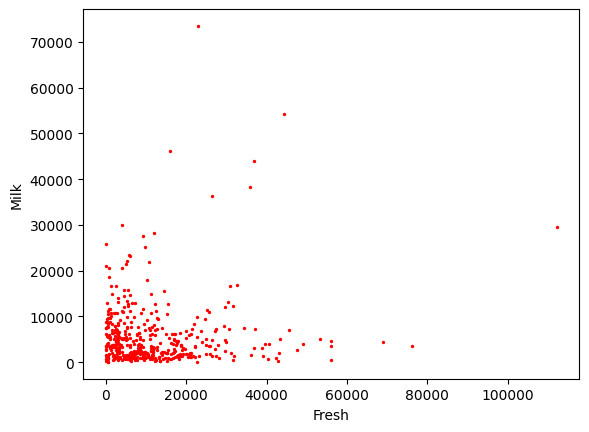

In [25]:
#scatter plot
plt.scatter(df['Fresh'],df['Milk'], c='red', s=2)
plt.xlabel("Fresh")
plt.ylabel("Milk")

In [26]:
#For now, we'll try k value 2
k=2
X=np.array(list(zip(df['Fresh'], df['Milk'])))
model=KMeans(n_clusters=k)
kmeans=model.fit(X)
labels=model.predict(X)
centroids=model.cluster_centers_
print(labels)
print(centroids)

[0 0 0 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 1 1 0 0 0 0 1 0 0 0 1 0 0 1
 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 1
 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 1 1 1 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 1 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0]
[[ 7962.7606383   5266.84042553]
 [35720.828125    8906.640625  ]]


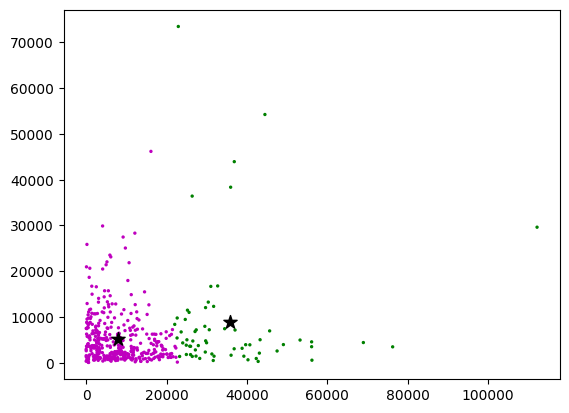

In [27]:
#Plot the data and centroids on a scatter plot
#map the labels to colors
c=['m','g','b','r','y','c']
colors=[c[i] for i in labels]
plt.scatter(df['Fresh'], df['Milk'], c=colors, s=2)
plt.scatter(centroids[:,0], centroids[:,1], marker='*', s=100, c='black')

Based on the result, we divided customers into two groups based on Fresh and Milk spending. The black stars show the centers of the two groups.

In [28]:
model.predict([[10000,5000]])

array([0], dtype=int32)

In [29]:
#To determine the silhouette coefficient/score

from sklearn.metrics import silhouette_score

model=KMeans(n_clusters=2)
model.fit(X)
label=model.predict(X)

print(f'silhouette Score (n=2): {silhouette_score(X,label)}')

model=KMeans(n_clusters=3)
model.fit(X)
label=model.predict(X)

print(f'silhouette Score (n=3): {silhouette_score(X,label)}')

model=KMeans(n_clusters=4)
model.fit(X)
label=model.predict(X)

print(f'silhouette Score (n=4): {silhouette_score(X,label)}')

silhouette Score (n=2): 0.5975629950955841
silhouette Score (n=3): 0.5485729680304876
silhouette Score (n=4): 0.42162842366694653


The highest value is K=2, so the ideal cluster number is 2.

But what if the management wants to divide customers into four groups to better understand their spending patterns? We can use K=4 to see four different customer groups.

[[13320.65       31068.15      ]
 [26291.36697248  4096.        ]
 [ 6138.37662338  4691.62012987]
 [85779.66666667 12503.66666667]]


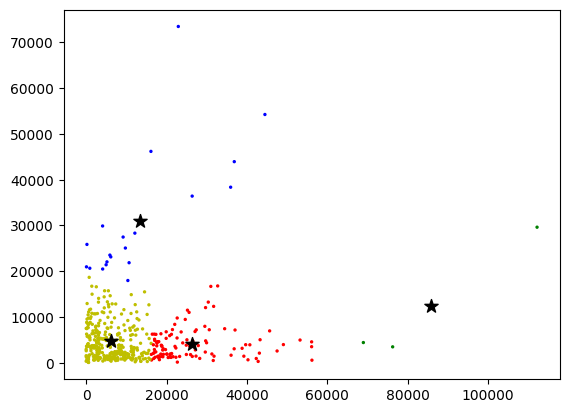

In [30]:
k=4
X=np.array(list(zip(df['Fresh'],df['Milk'])))

kmeans=KMeans(n_clusters=k)
kmeans=kmeans.fit(X)
labels=kmeans.predict(X)
centroids=kmeans.cluster_centers_

#map the labels to colors
c=['b','r','y','g','c','m']
colors=[c[i] for i in labels]

plt.scatter(df['Fresh'],df['Milk'],c=colors,s=2)
plt.scatter(centroids[:,0],centroids[:,1],marker='*',s=100,c='black')

print(centroids)

By using K=4, we come to the following four customer groups:

**Cluster 0 (Blue):** Fresh 13,320.65, Milk 31,068.15 - High Milk spending

**Cluster 1 (Red):** Fresh 26,291.37, Milk 4,096.00 - Higher Fresh spending than Milk

**Cluster 2 (Yellow):** Fresh 6,138.38, Milk 4,691.62 - Lowest Fresh spending

**Cluster 3 (Green):** Fresh 85,779.67, Milk 12,503.67 - Highest Fresh spending

**Summary**

This dataset has information about how much wholesale customers spend on different products. We used K-means clustering to group customers based on Fresh and Milk spending. First, we checked the data and removed missing values. Then, we made a scatter plot and used K=2 to divide customers into two groups. We compared silhouette scores for K=2, K=3, and K=4. K=2 had the highest score of 0.5976, so it was the best choice among these three values. However, we also used K=4 to divide customers into four groups. The results show different Fresh and Milk spending patterns. This can help the company understand its customers and make business decisions.